# 16.10 - Visual target annotation pilot

Manually inspect original-resolution images selected from the source train split. The occlusal checkpoint scores were used only to prioritize review. These are provisional visual research annotations by Codex, not orthodontist diagnoses or an independent validation set.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display
root=Path.cwd().resolve()
while not (root / "AGENTS.md").exists():
    if root==root.parent: raise RuntimeError("Project root not found")
    root=root.parent
base=root / "data/processed/alignment_omni_frontal_candidates"
queue=pd.read_csv(base / "review_queue.csv",dtype={"source_image_id":str,"sha256":str}).set_index("source_image_id")
excluded=set(pd.read_csv(root / "docs/reports/alignment/omni_frontal_candidate_audit/conservative_train_exclusions.csv",dtype=str).source_image_id)
print("Source train candidates:",sum(queue.split=="train"),"| conservative exclusions:",len(excluded))

Source train candidates: 538 | conservative exclusions: 34


## 1. Record visible targets with explicit box coordinates

A midline gap box surrounds both upper central incisors. A crowding box includes the displaced anterior tooth and adjacent teeth. Borderline findings are omitted from this initial positive pilot. An omitted target has unknown status, never an assumed negative.

In [2]:
proposals = pd.DataFrame([
    ("201916202112081", "upper_midline_diastema", 174, 90, 326, 190, "visible central separation"),
    ("202139202205251", "upper_midline_diastema", 183, 120, 337, 195, "visible central separation"),
    ("202212202202071", "upper_midline_diastema", 173, 122, 303, 185, "visible central separation"),
    ("202362202308141", "upper_midline_diastema", 173, 128, 335, 205, "visible central separation"),
    ("202244202207131", "anterior_crowding", 255, 85, 425, 190, "visible anterior displacement and overlap"),
], columns=["source_image_id","target","x_min","y_min","x_max","y_max","visual_reason"])
proposals["reviewer"]="Codex visual review"
proposals["review_state"]="agent_visual_provisional"
for row in proposals.itertuples():
    source=queue.loc[row.source_image_id]
    assert source["split"]=="train" and row.source_image_id not in excluded
    assert 0<=row.x_min<row.x_max<=int(source["width"]) and 0<=row.y_min<row.y_max<=int(source["height"])
    image=root / source["image_path"]
    assert hashlib.sha256(image.read_bytes()).hexdigest()==source["sha256"]
print("Checked visual proposals:",len(proposals))
display(proposals)

Checked visual proposals: 5


,source_image_id,target,x_min,y_min,x_max,y_max,visual_reason,reviewer,review_state
0,201916202112081,upper_midline_diastema,174,90,326,190,visible central separation,Codex visual review,agent_visual_provisional
1,202139202205251,upper_midline_diastema,183,120,337,195,visible central separation,Codex visual review,agent_visual_provisional
2,202212202202071,upper_midline_diastema,173,122,303,185,visible central separation,Codex visual review,agent_visual_provisional
3,202362202308141,upper_midline_diastema,173,128,335,205,visible central separation,Codex visual review,agent_visual_provisional
4,202244202207131,anterior_crowding,255,85,425,190,visible anterior displacement and overlap,Codex visual review,agent_visual_provisional


## 2. Verify overlays

Review each proposed box on the original image. This visual QA checks coordinates; it does not turn the annotation into a clinical ground truth.

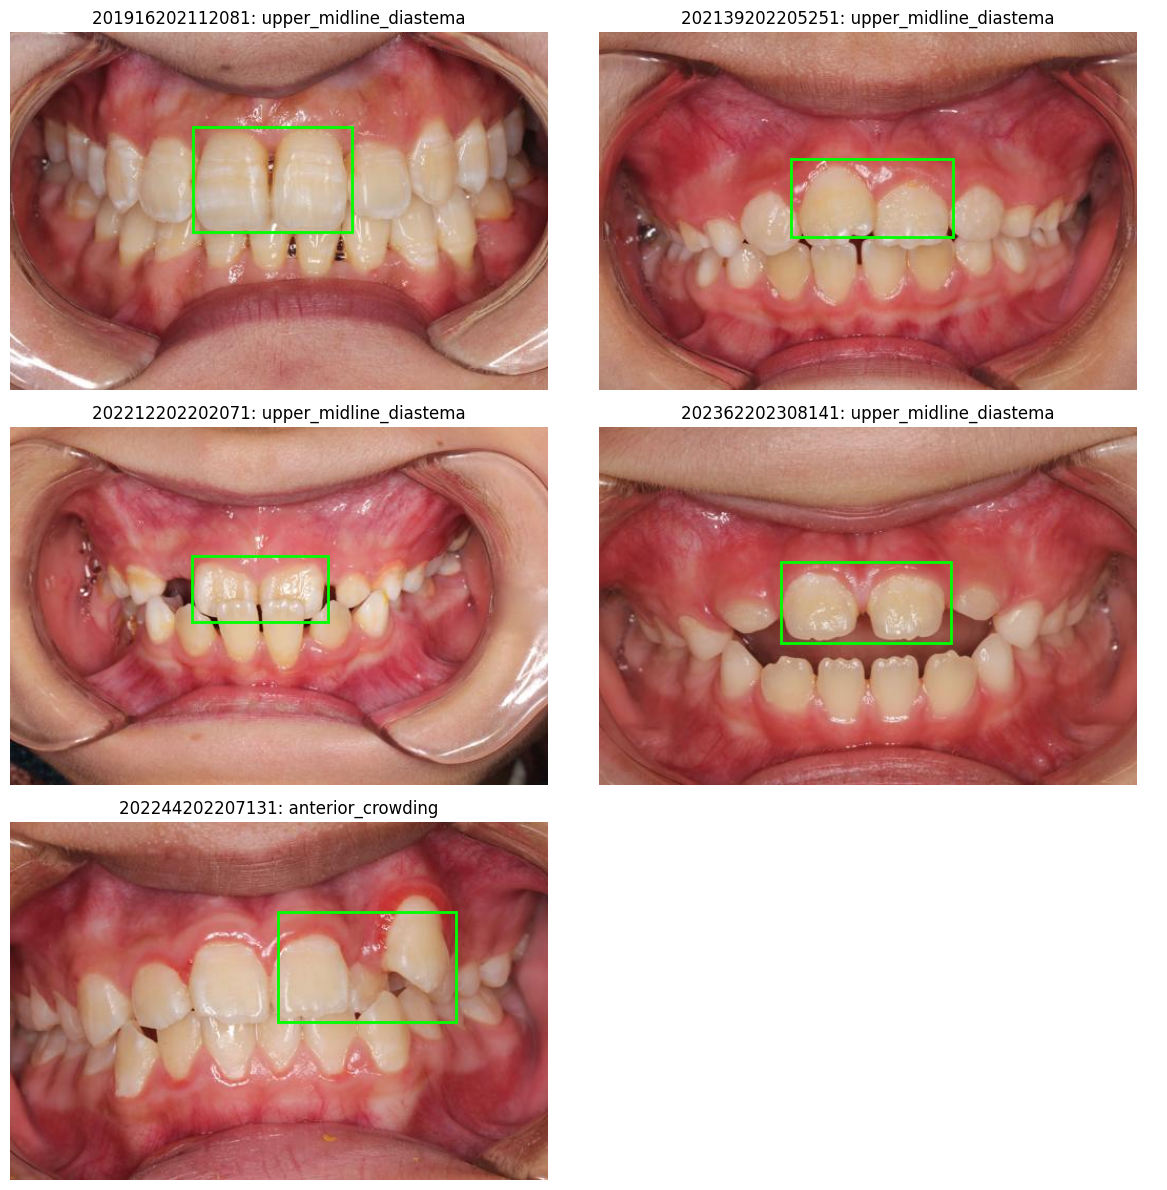

In [3]:
fig, axes=plt.subplots(3,2,figsize=(12,12))
for ax,row in zip(axes.flat,proposals.itertuples()):
    image=Image.open(root / queue.loc[row.source_image_id,"image_path"])
    ax.imshow(image)
    ax.add_patch(plt.Rectangle((row.x_min,row.y_min),row.x_max-row.x_min,row.y_max-row.y_min,fill=False,edgecolor="lime",linewidth=2))
    ax.set_title(f"{row.source_image_id}: {row.target}")
    ax.axis("off")
for ax in list(axes.flat)[len(proposals):]: ax.axis("off")
fig.tight_layout()
out=root / "docs/reports/alignment/agent_visual_pilot"
out.mkdir(parents=True,exist_ok=True)
fig.savefig(out / "provisional_boxes.png",dpi=140)
plt.show()
plt.close(fig)

## 3. Save provisional evidence

Store this separate from the approved review queue. It can seed exploratory training after the annotation protocol and class coverage are reviewed; it is not ready for final accuracy claims.

In [4]:
path=out / "agent_visual_proposals.csv"
if path.exists():
    old=pd.read_csv(path,dtype={"source_image_id":str})
    assert old.equals(proposals), "Existing proposals differ; review rather than overwrite"
else: proposals.to_csv(path,index=False)
print("Saved:",path)
print("Visual positives per target:")
display(proposals.groupby("target").size().to_frame("provisional_boxes"))

Saved: C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\agent_visual_pilot\agent_visual_proposals.csv
Visual positives per target:


,provisional_boxes
target,
anterior_crowding,1
upper_midline_diastema,4
